# 10. Modelo avanzado: Transformer

Este notebook desarrolla únicamente el **apartado 3.1**: un codificador Transformer con codificación posicional y token de máquina, entrenado para las mismas dos tareas a 24 horas. Lo comparamos en validación con los resultados guardados de la segunda entrega.

La incertidumbre, la calibración, la interpretabilidad y la política económica se revisarán en sus propios pasos. No abrimos prueba, no modificamos los CSV preparados y no elaboramos todavía el reporte final.

## 1. Por qué elegimos esta opción

Elegimos el **Transformer supervisado** porque permite estudiar otra forma de procesar las mismas ventanas y etiquetas. La atención puede combinar información de distintas posiciones de la historia sin depender de una recurrencia LSTM. Es una hipótesis de modelado, no una garantía de superar XGBoost o CNN-LSTM.

Las otras opciones también son válidas, pero cambian más elementos del problema: el autoencoder aprende reconstrucción usando ventanas sanas, y el modelo de tiempo hasta falla requiere otro objetivo y reglas de seguimiento o censura. Aquí conservamos las dos tareas de clasificación y cambiamos principalmente el codificador.

La idea de atención y codificación posicional proviene de [Vaswani et al., Attention Is All You Need](https://arxiv.org/abs/1706.03762). Utilizamos la capa oficial [TransformerEncoderLayer de PyTorch](https://docs.pytorch.org/docs/2.15/generated/torch.nn.TransformerEncoderLayer.html). El token condicionado por modelo de máquina y antigüedad es una adaptación para este proyecto.

## 2. Recuperar los mismos datos

Reutilizamos `preparar_secuencias.py`: reconstruye los cuatro sensores, cinco indicadores horarios de error y cuatro tiempos desde reemplazo. Las transformaciones se aprenden solo con entrenamiento. Los CSV preparados aportan las claves y las etiquetas; permanecen intactos.

Trabajamos con **24 horas**, porque fue la mejor longitud de CNN-LSTM en la comparación previa y limita el costo de la atención, que crece con las parejas de posiciones de la ventana. Usamos las mismas **563,500 anclas comunes** de las redes anteriores y las mismas **144,000 horas de validación**. No cambiamos la partición temporal ni seleccionamos otra muestra.

In [1]:
from pathlib import Path
import sys
import math
import copy
import time
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, classification_report)

# Localizar los archivos desde la raíz del proyecto o desde Modelación.
actual = Path.cwd()
if (actual / "Datos").is_dir():
    ruta_repo = actual
elif (actual.parent / "Datos").is_dir():
    ruta_repo = actual.parent
else:
    raise FileNotFoundError("No se encontró la carpeta Datos.")
for carpeta in ["Preprocesamiento", "Modelación"]:
    ruta = str(ruta_repo / carpeta)
    if ruta not in sys.path:
        sys.path.insert(0, ruta)

from preparar_secuencias import preparar_secuencias
from entrenamiento_secuencial import (indices_comunes, calcular_pesos, PerdidaDesbalanceada,
                                      fijar_semilla, predecir)

# Reconstruir la preparación con las funciones existentes, sin leer prueba.
preparacion_10 = preparar_secuencias(ruta_repo)
indices_10 = indices_comunes(preparacion_10)
comunes_10 = preparacion_10["anclas"][168]["entrenamiento"]
entrenamiento_10 = Subset(preparacion_10["datasets"][24]["entrenamiento"], indices_10[24])
validacion_10 = preparacion_10["datasets"][24]["validación"]
clases = ["ninguno", "comp1", "comp2", "comp3", "comp4"]
assert len(entrenamiento_10) == 563500 and len(validacion_10) == 144000
pd.set_option("display.max_columns", 15)
pd.set_option("display.precision", 6)
plt.rcParams["figure.dpi"] = 160
display(pd.DataFrame({"conjunto": ["entrenamiento", "validación"],
                      "ejemplos": [len(entrenamiento_10), len(validacion_10)],
                      "horas_por_ventana": [24, 24], "canales": [13, 13]}))

,conjunto,ejemplos,horas_por_ventana,canales
0,entrenamiento,563500,24,13
1,validación,144000,24,13


Cada ejemplo sigue correspondiendo a una máquina y hora `t`. Su ventana termina en `t` y contiene las mediciones desde `t − 23` hasta `t`. El objetivo es una falla en `(t, t + 24 h]`. Las estadísticas de normalización se ajustan con las 580,200 claves originales de entrenamiento; exigir historia común para entrenar las redes no utiliza validación ni reajusta esas estadísticas.

## 3. Cómo entra la historia al Transformer

### Proyección de los 13 canales

Cada hora contiene 13 números. Una capa `Linear(13, 32)` los convierte en una representación de 32 números que la atención puede procesar. Esta proyección se aprende al entrenar; no agrega nuevas mediciones ni etiquetas.

### Codificación posicional

La posición indica qué lugar ocupa una hora dentro de la ventana. Añadimos un vector fijo de senos y cosenos a la representación de cada hora. Así, dos valores iguales en posiciones distintas no tienen una entrada idéntica. No son fechas futuras ni variables calculadas con las fallas.

Para posición `p` y par de dimensiones `i`, usamos `sin(p / 10000^(2i/32))` y `cos(p / 10000^(2i/32))`. Elegimos esta codificación fija para expresar el orden sin aprender una tabla adicional de posiciones. Se guarda como un buffer: acompaña al modelo, pero no se aprende por gradientes.

### Token de máquina

Agregamos al final **un elemento de resumen** construido con el embedding del modelo de máquina y la antigüedad normalizada, ambos proyectados a 32 números. También tiene un vector base aprendido. No introducimos `machineID` como predictor.

El embedding del modelo usa 32 dimensiones para poder sumarse a la proyección de edad y al token base. Las redes anteriores usaban un embedding de cuatro números concatenado al estado final; esta adaptación también debe reconocerse al comparar arquitecturas.

Este token no representa una hora adicional ni `t + 1`: es una posición especial que consulta la historia y sirve para obtener las dos respuestas. Una ventana de 24 horas produce **25 elementos internos**: 24 de mediciones y uno de máquina.

### Máscara causal y dos salidas

Usamos dos bloques de atención con cuatro cabezas, 32 dimensiones y una capa interna de 64 unidades. Cada cabeza trabaja con 8 dimensiones. La máscara impide que un estado horario consulte posiciones posteriores; el token final sí puede consultar todas las horas observadas y sus atributos estáticos.

Cada bloque combina atención y una transformación por posición, con conexiones residuales y LayerNorm. Esta normalización opera sobre los 32 valores de cada posición; no calcula estadísticas globales usando validación.

El estado del token pasa a una capa compartida de 32 unidades y a dos cabezas: un logit binario y cinco logits multiclase. Conservamos las dos tareas de la etapa anterior. No necesitamos un decoder porque clasificamos una ventana observada; no generamos una secuencia nueva.

La definición siguiente usa el mismo estilo del ejemplo de clase: capas en `__init__` y recorrido en `forward`. El método auxiliar `codificar_secuencia` permite revisar los estados antes de las cabezas.

In [2]:
class CodificacionPosicional(nn.Module):
    """Representar el orden relativo con senos y cosenos fijos."""

    def __init__(self, dimension=32, max_horas=168):
        super().__init__()
        assert dimension % 2 == 0
        posiciones = torch.arange(max_horas, dtype=torch.float32).unsqueeze(1)
        frecuencias = torch.exp(torch.arange(0, dimension, 2, dtype=torch.float32)
                                * (-math.log(10000.0) / dimension))
        codificacion = torch.zeros(max_horas, dimension)
        codificacion[:, 0::2] = torch.sin(posiciones * frecuencias)
        codificacion[:, 1::2] = torch.cos(posiciones * frecuencias)

        # El buffer forma parte del estado del modelo, pero no es un parámetro entrenable.
        self.register_buffer("codificacion", codificacion.unsqueeze(0))

    def forward(self, x):
        longitud = x.shape[1]
        return x + self.codificacion[:, :longitud, :]


class TransformerMantenimiento(nn.Module):
    """Codificador causal con token de máquina y cabezas binaria y multiclase."""

    def __init__(self, numero_modelos, dimension=32, cabezas=4, capas=2,
                 internas=64, dropout=0.10, max_horas=168):
        super().__init__()
        assert dimension % cabezas == 0
        self.proyectar_sensores = nn.Linear(13, dimension)
        self.posiciones = CodificacionPosicional(dimension, max_horas)
        self.embedding_modelo = nn.Embedding(numero_modelos, dimension, padding_idx=0)
        self.proyectar_edad = nn.Linear(1, dimension)
        self.token_base = nn.Parameter(torch.zeros(1, 1, dimension))
        self.dropout_entrada = nn.Dropout(dropout)

        # Crear cada bloque por separado le da su propia inicialización aleatoria.
        self.bloques = nn.ModuleList()
        for numero in range(capas):
            bloque = nn.TransformerEncoderLayer(
                d_model=dimension, nhead=cabezas, dim_feedforward=internas,
                dropout=dropout, activation="relu", batch_first=True,
            )
            self.bloques.append(bloque)

        # True bloquea una conexión hacia una posición posterior.
        mascara = torch.triu(torch.ones(max_horas + 1, max_horas + 1, dtype=torch.bool), diagonal=1)
        self.register_buffer("mascara_causal", mascara)
        self.compartida = nn.Sequential(nn.Linear(dimension, 32), nn.ReLU(), nn.Dropout(dropout))
        self.salida_binaria = nn.Linear(32, 1)
        self.salida_multiclase = nn.Linear(32, 5)

    def codificar_secuencia(self, dinamicas, modelo, edad):
        horas = self.posiciones(self.proyectar_sensores(dinamicas))
        atributos = self.embedding_modelo(modelo) + self.proyectar_edad(edad)
        token_maquina = self.token_base + atributos.unsqueeze(1)
        secuencia = torch.cat([horas, token_maquina], dim=1)
        estados = self.dropout_entrada(secuencia)
        longitud = estados.shape[1]
        mascara = self.mascara_causal[:longitud, :longitud]
        for bloque in self.bloques:
            estados = bloque(estados, src_mask=mascara)
        return estados

    def forward(self, dinamicas, modelo, edad):
        estados = self.codificar_secuencia(dinamicas, modelo, edad)

        # La última posición es el token de máquina; no una medición futura.
        resumen = estados[:, -1, :]
        compartida = self.compartida(resumen)
        return {"binaria": self.salida_binaria(compartida),
                "multiclase": self.salida_multiclase(compartida)}

## 4. Justificar el tamaño y las reglas del ajuste

Usamos **32 dimensiones, cuatro cabezas y dos bloques** para mantener una red pequeña, con una representación del mismo tamaño que las redes anteriores. Cuatro cabezas permiten cuatro combinaciones de atención; no significan un sensor por cabeza ni una explicación automática del modelo. Las 64 unidades internas ofrecen una transformación adicional sin usar la configuración grande de propósito general.

Este paso tendrá **un solo ensayo**, con hasta seis épocas. No buscamos nuevos valores de longitud, profundidad o tasa de aprendizaje después de ver el resultado. Mantener 24 horas y las reglas del 08 facilita la comparación y limita el costo.

Conservamos pérdida ponderada, pesos calculados solo con las anclas comunes y combinación `0.60 × binaria + 0.40 × multiclase`. La ponderación fue la estrategia de la mejor CNN-LSTM previa y el mayor coeficiente binario mantiene la prioridad de anticipar cualquier falla. Ninguna decisión se toma con prueba.

Reutilizar AdamW, dropout, weight decay y early stopping es necesario para entrenar bajo las reglas ya establecidas. No inicia aquí el apartado de incertidumbre ni una nueva comparación de desbalance.

In [3]:
configuracion_10 = {"semilla": 42, "hilos": 1, "L": 24, "dimension": 32,
                    "cabezas": 4, "capas": 2, "internas": 64, "dropout": 0.10,
                    "batch_size": 512, "max_epocas": 6, "paciencia": 2,
                    "min_delta": 0.0001, "learning_rate": 0.001, "weight_decay": 0.0001}

def crear_transformer():
    """Construir la configuración declarada, sin cambiar las opciones entre épocas."""
    return TransformerMantenimiento(
        preparacion_10["numero_codigos_modelo"], dimension=configuracion_10["dimension"],
        cabezas=configuracion_10["cabezas"], capas=configuracion_10["capas"],
        internas=configuracion_10["internas"], dropout=configuracion_10["dropout"],
    )


# Las pruebas usan otra instancia; el entrenamiento comienza después con semilla reiniciada.
fijar_semilla(configuracion_10["semilla"])
torch.set_num_threads(configuracion_10["hilos"])
modelo_revision = crear_transformer()
pesos_binarios_10, pesos_multi_10 = calcular_pesos(comunes_10)
criterio_10 = PerdidaDesbalanceada(pesos_binarios_10, pesos_multi_10, "ponderada")
numero_parametros = sum(parametro.numel() for parametro in modelo_revision.parameters() if parametro.requires_grad)
display(pd.DataFrame({"parámetro": list(configuracion_10), "valor": list(configuracion_10.values())}))
print("Parámetros entrenables:", numero_parametros)
print(modelo_revision)

,parámetro,valor
0,semilla,42.0000
1,hilos,1.0000
2,L,24.0000
3,dimension,32.0000
4,cabezas,4.0000
5,capas,2.0000
6,internas,64.0000
7,dropout,0.1000
8,batch_size,512.0000
9,max_epocas,6.0000


Parámetros entrenables: 19046
TransformerMantenimiento(
  (proyectar_sensores): Linear(in_features=13, out_features=32, bias=True)
  (posiciones): CodificacionPosicional()
  (embedding_modelo): Embedding(5, 32, padding_idx=0)
  (proyectar_edad): Linear(in_features=1, out_features=32, bias=True)
  (dropout_entrada): Dropout(p=0.1, inplace=False)
  (bloques): ModuleList(
    (0-1): 2 x TransformerEncoderLayer(
      (self_attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
      )
      (linear1): Linear(in_features=32, out_features=64, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (linear2): Linear(in_features=64, out_features=32, bias=True)
      (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
      (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
      (dropout1): Dropout(p=0.1, inplace=False)
      (dropout2): Dropout(p=0.1, inplace=False)
    )
  

## 5. Comprobar la arquitectura antes de entrenar

Revisamos formas, gradientes y causalidad con un lote pequeño de entrenamiento. Esto no selecciona ejemplos para el ajuste final ni actualiza pesos. También comprobamos que la posición cambia entre horas y que la predicción de una ventana no depende de las otras ventanas del lote.

Al cambiar la segunda mitad de las horas observadas, los estados anteriores deben permanecer iguales. El estado final de resumen puede cambiar, porque utiliza toda la historia hasta `t`. La prueba no supone que el token sea una hora nueva.

In [4]:
lote_revision = next(iter(DataLoader(entrenamiento_10, batch_size=4, shuffle=False)))
modelo_revision.train()
salidas_revision = modelo_revision(lote_revision["dinamicas"], lote_revision["modelo"], lote_revision["edad"])
assert salidas_revision["binaria"].shape == (4, 1)
assert salidas_revision["multiclase"].shape == (4, 5)
perdidas_revision = criterio_10(salidas_revision, lote_revision)
assert torch.isfinite(perdidas_revision["total"])
perdidas_revision["total"].backward()

# Ambas cabezas y el codificador deben recibir gradientes finitos.
for capa in [modelo_revision.salida_binaria, modelo_revision.salida_multiclase,
             modelo_revision.proyectar_sensores, modelo_revision.proyectar_edad]:
    assert capa.weight.grad is not None and torch.isfinite(capa.weight.grad).all()
    assert capa.weight.grad.abs().sum() > 0
assert not torch.equal(modelo_revision.posiciones.codificacion[:, 0], modelo_revision.posiciones.codificacion[:, 1])
assert not torch.equal(modelo_revision.bloques[0].linear1.weight, modelo_revision.bloques[1].linear1.weight)

# Desactivar dropout permite contrastar las mismas operaciones sin ruido aleatorio.
modelo_revision.eval()
original = lote_revision["dinamicas"][:2].clone()
modificada = original.clone()
corte = 12
modificada[:, corte:, :] += 10
with torch.no_grad():
    estados_originales = modelo_revision.codificar_secuencia(original, lote_revision["modelo"][:2], lote_revision["edad"][:2])
    estados_modificados = modelo_revision.codificar_secuencia(modificada, lote_revision["modelo"][:2], lote_revision["edad"][:2])
    diferencia_pasado = (estados_originales[:, :corte] - estados_modificados[:, :corte]).abs().max().item()
    assert diferencia_pasado < 0.000001
    juntas = modelo_revision(original, lote_revision["modelo"][:2], lote_revision["edad"][:2])
    sola = modelo_revision(original[:1], lote_revision["modelo"][:1], lote_revision["edad"][:1])
    assert torch.allclose(juntas["binaria"][:1], sola["binaria"], atol=0.000001)
    assert estados_originales.shape == (2, 25, 32)

display(pd.DataFrame({"comprobación": ["Salida binaria", "Salida multiclase", "Estados con token", "Cambio máximo en el pasado"],
                      "resultado": [str(tuple(salidas_revision["binaria"].shape)), str(tuple(salidas_revision["multiclase"].shape)),
                                    str(tuple(estados_originales.shape)), f"{diferencia_pasado:.8f}"]}))
print("Gradientes, posiciones, inicialización de bloques e independencia entre ejemplos: correctos.")

,comprobación,resultado
0,Salida binaria,"(4, 1)"
1,Salida multiclase,"(4, 5)"
2,Estados con token,"(2, 25, 32)"
3,Cambio máximo en el pasado,0.00000000


Gradientes, posiciones, inicialización de bloques e independencia entre ejemplos: correctos.


La red tiene **19,046 parámetros entrenables**. El lote de cuatro ejemplos produjo logits **4 × 1** y **4 × 5** y estados **2 × 25 × 32** en la comprobación de dos ventanas. Los gradientes fueron finitos en las dos cabezas y las capas revisadas.

Al modificar la segunda mitad de la ventana, la diferencia máxima en los estados anteriores fue **0.00000000**. Las posiciones no son iguales entre horas, los dos bloques tienen inicializaciones propias y un ejemplo conserva su salida al evaluarlo solo o junto a otro. Estas comprobaciones verifican la implementación; no son métricas de desempeño.

## 6. Diagrama del modelo

La máscara conserva el orden causal. Las 24 representaciones horarias y el token de máquina pasan por los mismos dos bloques; únicamente el estado final del token alimenta las cabezas.

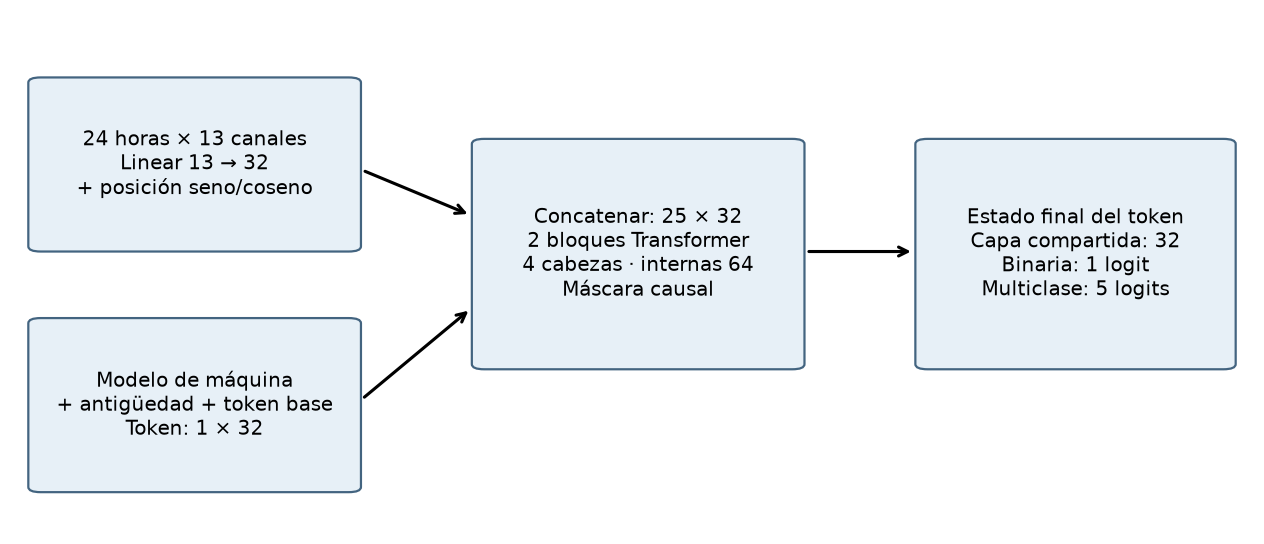

In [5]:
fig, eje = plt.subplots(figsize=(8, 3.5))
eje.axis("off")
cajas = [(.02, .55, .25, .32, "24 horas × 13 canales\nLinear 13 → 32\n+ posición seno/coseno"),
         (.02, .08, .25, .32, "Modelo de máquina\n+ antigüedad + token base\nToken: 1 × 32"),
         (.38, .32, .25, .43, "Concatenar: 25 × 32\n2 bloques Transformer\n4 cabezas · internas 64\nMáscara causal"),
         (.74, .32, .24, .43, "Estado final del token\nCapa compartida: 32\nBinaria: 1 logit\nMulticlase: 5 logits")]
for x, y, ancho, alto, texto in cajas:
    eje.add_patch(FancyBboxPatch((x, y), ancho, alto, boxstyle="round,pad=0.01", facecolor="#e7f0f7", edgecolor="#436480"))
    eje.text(x + ancho / 2, y + alto / 2, texto, ha="center", va="center", fontsize=9)
for inicio, fin in [((.28, .70), (.37, .61)), ((.28, .25), (.37, .43)), ((.64, .54), (.73, .54))]:
    eje.annotate("", xy=fin, xytext=inicio, arrowprops={"arrowstyle": "->", "lw": 1.4})
eje.set(xlim=(0, 1), ylim=(0, 1))
fig.tight_layout()
plt.show()

## 7. Entrenar el único ensayo declarado

El ajuste recorre todas las anclas comunes en cada época. La validación se evalúa sin permutar ni remuestrear, con dropout desactivado. Elegimos la mejor época por PR-AUC de validación (average precision).

Usamos paciencia 2 y mejora de referencia 0.0001. Dos épocas consecutivas sin mejora suficiente detienen el ajuste; siempre recuperamos el estado con mayor PR-AUC real, incluso si una mejora pequeña no reinicia la paciencia. La norma del gradiente se limita a 1.0. Ninguna de estas reglas consulta prueba.

In [6]:
def entrenar_transformer():
    """Entrenar una configuración y conservar su mejor estado por PR-AUC de validación."""
    fijar_semilla(configuracion_10["semilla"])
    modelo = crear_transformer()
    criterio = PerdidaDesbalanceada(pesos_binarios_10, pesos_multi_10, "ponderada")
    optimizador = torch.optim.AdamW(modelo.parameters(), lr=configuracion_10["learning_rate"],
                                    weight_decay=configuracion_10["weight_decay"])
    generador = torch.Generator().manual_seed(configuracion_10["semilla"])
    cargador_train = DataLoader(entrenamiento_10, batch_size=configuracion_10["batch_size"],
                               shuffle=True, generator=generador, num_workers=0)
    cargador_val = DataLoader(validacion_10, batch_size=configuracion_10["batch_size"],
                             shuffle=False, num_workers=0)
    mejor_ap = -np.inf
    mejor_estado = None
    mejor_epoca = 0
    sin_mejora = 0
    historial = []
    inicio_ajuste = time.perf_counter()
    for epoca in range(1, configuracion_10["max_epocas"] + 1):
        inicio_epoca = time.perf_counter()
        modelo.train()
        sumas = {"total": 0.0, "binaria": 0.0, "multiclase": 0.0}
        procesados = 0
        for numero_lote, lote in enumerate(cargador_train, start=1):
            optimizador.zero_grad(set_to_none=True)
            salidas = modelo(lote["dinamicas"], lote["modelo"], lote["edad"])
            perdidas = criterio(salidas, lote)
            assert torch.isfinite(perdidas["total"])
            perdidas["total"].backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0, error_if_nonfinite=True)
            optimizador.step()
            cantidad = len(lote["modelo"])
            procesados += cantidad
            for nombre in sumas:
                sumas[nombre] += perdidas[nombre].item() * cantidad
            if numero_lote % 300 == 0:
                print("Transformer | época", epoca, "| lotes", numero_lote, "/", len(cargador_train), flush=True)
        assert procesados == len(entrenamiento_10)
        evaluacion = predecir(modelo, cargador_val, criterio)
        ap = average_precision_score(evaluacion["y_binaria"], evaluacion["prob_binaria"])
        fila = {"epoca": epoca, "PR_AUC_validacion": ap, "segundos": time.perf_counter() - inicio_epoca}
        for nombre in sumas:
            fila["train_" + nombre] = sumas[nombre] / procesados
            fila["val_" + nombre] = evaluacion["perdidas"][nombre]
        historial.append(fila)
        print("Transformer | FIN época", epoca, "| PR-AUC", round(ap, 6), "| segundos", round(fila["segundos"], 1), flush=True)

        # La paciencia y el mejor estado se controlan con la misma regla del notebook 08.
        suficiente = ap > mejor_ap + configuracion_10["min_delta"]
        if ap > mejor_ap:
            mejor_ap = ap
            mejor_estado = copy.deepcopy(modelo.state_dict())
            mejor_epoca = epoca
        sin_mejora = 0 if suficiente else sin_mejora + 1
        if sin_mejora >= configuracion_10["paciencia"]:
            print("Parada temprana activada.", flush=True)
            break
    modelo.load_state_dict(mejor_estado)
    predicciones = predecir(modelo, cargador_val, criterio)
    return {"modelo": modelo, "historial": pd.DataFrame(historial), "predicciones": predicciones,
            "mejor_epoca": mejor_epoca, "epocas_ejecutadas": len(historial),
            "segundos_totales": time.perf_counter() - inicio_ajuste}


# Este es el único ajuste del paso 3.1; no cambia el presupuesto según su resultado.
resultado_transformer = entrenar_transformer()
historial_transformer = resultado_transformer["historial"]
display(historial_transformer.round(6))
print("Épocas ejecutadas:", resultado_transformer["epocas_ejecutadas"])
print("Mejor época conservada:", resultado_transformer["mejor_epoca"])

Transformer | época 1 | lotes 300 / 1101
Transformer | época 1 | lotes 600 / 1101
Transformer | época 1 | lotes 900 / 1101
Transformer | FIN época 1 | PR-AUC 0.896957 | segundos 152.2
Transformer | época 2 | lotes 300 / 1101
Transformer | época 2 | lotes 600 / 1101
Transformer | época 2 | lotes 900 / 1101
Transformer | FIN época 2 | PR-AUC 0.995518 | segundos 147.9
Transformer | época 3 | lotes 300 / 1101
Transformer | época 3 | lotes 600 / 1101
Transformer | época 3 | lotes 900 / 1101
Transformer | FIN época 3 | PR-AUC 0.992549 | segundos 158.1
Transformer | época 4 | lotes 300 / 1101
Transformer | época 4 | lotes 600 / 1101
Transformer | época 4 | lotes 900 / 1101
Transformer | FIN época 4 | PR-AUC 0.992861 | segundos 145.6
Parada temprana activada.


,epoca,PR_AUC_validacion,segundos,train_total,val_total,train_binaria,val_binaria,train_multiclase,val_multiclase
0,1,0.896957,152.237804,0.205965,0.051569,0.175999,0.051994,0.250914,0.050932
1,2,0.995518,147.891709,0.043319,0.014062,0.039883,0.007921,0.048475,0.023274
2,3,0.992549,158.137735,0.015949,0.010642,0.014527,0.006612,0.018083,0.016688
3,4,0.992861,145.601748,0.012172,0.011404,0.011757,0.005622,0.012795,0.020077


Épocas ejecutadas: 4
Mejor época conservada: 2


El ensayo completó **4 épocas** con todas las **563,500 ventanas de entrenamiento** y las mismas **144,000 de validación**. Se conservó la época **2**, con PR-AUC **0.9955**.

Se activó early stopping antes del máximo de seis épocas. Las métricas posteriores se calculan con el estado de la mejor época, no con el último estado entrenado.

No se añadió una búsqueda ni se modificaron los datos o los parámetros según la evaluación.

Las épocas 3 y 4 no superaron la mejor PR-AUC de la época 2. Aunque la cuarta mejoró ligeramente frente a la tercera, no mejoró frente al mejor valor conservado; por eso se agotó la paciencia de dos épocas.

## 8. Revisar las curvas de aprendizaje

PR-AUC debe interpretarse con sus pérdidas. Una pérdida de entrenamiento menor junto con una de validación creciente puede indicar sobreajuste. Las dos tareas también se muestran por separado para comprobar que los coeficientes 0.60 y 0.40 no oculten el comportamiento de una cabeza.

Estas curvas describen el único ensayo; no se usan para ampliar el presupuesto después de verlo.

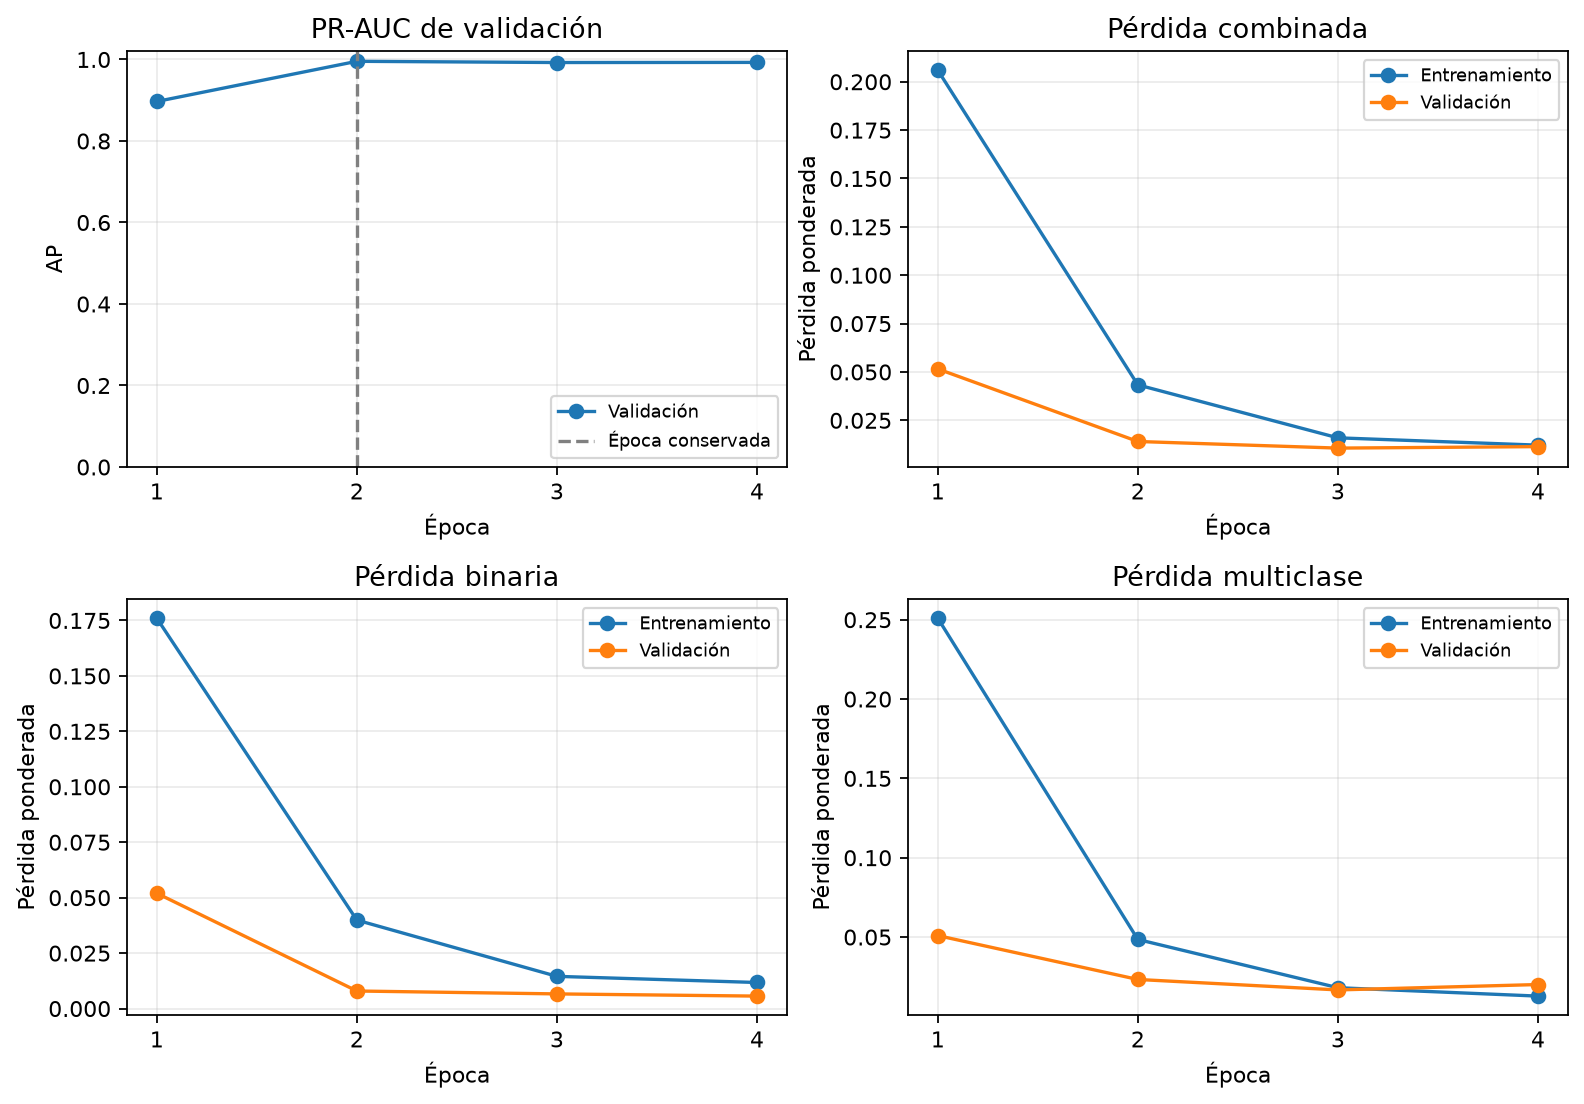

In [7]:
fig, ejes = plt.subplots(2, 2, figsize=(10, 7))
h = historial_transformer
mejor_epoca_10 = resultado_transformer["mejor_epoca"]
ejes[0, 0].plot(h["epoca"], h["PR_AUC_validacion"], marker="o", label="Validación")
ejes[0, 0].axvline(mejor_epoca_10, color="gray", linestyle="--", label="Época conservada")
eje = ejes[0, 0]
eje.set(title="PR-AUC de validación", xlabel="Época", ylabel="AP", ylim=(0, 1.02))
eje.legend(fontsize=8)
for eje, nombre, titulo in [(ejes[0, 1], "total", "Pérdida combinada"),
                            (ejes[1, 0], "binaria", "Pérdida binaria"),
                            (ejes[1, 1], "multiclase", "Pérdida multiclase")]:
    eje.plot(h["epoca"], h["train_" + nombre], marker="o", label="Entrenamiento")
    eje.plot(h["epoca"], h["val_" + nombre], marker="o", label="Validación")
    eje.set(title=titulo, xlabel="Época", ylabel="Pérdida ponderada")
    eje.legend(fontsize=8)
for eje in ejes.flat:
    eje.set_xticks(h["epoca"])
    eje.grid(alpha=.25)
fig.tight_layout()
plt.show()

PR-AUC pasó de **0.8970** en la primera época a **0.9929** en la última ejecutada. La época conservada fue la **2**. La pérdida combinada de entrenamiento cambió de **0.20596** a **0.01217**, y la de validación de **0.05157** a **0.01140**.

Al final, la pérdida de validación subió mientras la de entrenamiento bajó. Esa separación es una señal para vigilar el sobreajuste; no cambia la regla de conservar la época por PR-AUC.

Las pérdidas binaria y multiclase se muestran por separado porque sus coeficientes no aseguran igual influencia. La validación ya participa en elegir época; no es una evaluación independiente.

La pérdida multiclase de validación pasó de **0.01669** a **0.02008** en la última época, mientras la binaria bajó de **0.00661** a **0.00562**. Las dos tareas no evolucionan exactamente igual; la regla de selección sigue siendo AP binaria.

## 9. Evaluar las dos tareas y comparar con la entrega anterior

Calculamos AP, ROC-AUC y recall con precisión horaria de al menos 0.80. El umbral maximiza recall entre los puntos reales de la curva que cumplen la restricción. Se elige y mide en validación, por lo que es un resultado de desarrollo, no la política económica final.

Para multiclase usamos argmax, mostramos F1 por componente y promedios de cinco clases y de los cuatro componentes. Las métricas de referencia se leen de las tablas guardadas del notebook 09: no volvemos a entrenar los modelos clásicos ni las otras redes.

La línea base usó 580,200 filas de entrenamiento; las redes usan 563,500 anclas comunes. Las representaciones y presupuestos también difieren. La comparación de procedimientos es útil, pero no aísla únicamente el efecto de atención frente a recurrencia.

In [8]:
pred_10 = resultado_transformer["predicciones"]
y_bin_10 = pred_10["y_binaria"].astype(int)
y_multi_10 = pred_10["y_multiclase"].astype(int)
p_bin_10 = pred_10["prob_binaria"]
p_multi_10 = pred_10["prob_multiclase"]
assert len(p_bin_10) == 144000 and np.isfinite(p_bin_10).all()
assert np.allclose(p_multi_10.sum(axis=1), 1, atol=0.00001)
precision, recall, umbrales = precision_recall_curve(y_bin_10, p_bin_10)
candidatos = np.flatnonzero(precision[:-1] >= .80)
umbral_10 = None
precision_10 = np.nan
recall_10 = np.nan
if len(candidatos):
    elegido = candidatos[np.argmax(recall[:-1][candidatos])]
    umbral_10 = float(umbrales[elegido])
    alertas_10 = p_bin_10 >= umbral_10
    precision_10 = precision_score(y_bin_10, alertas_10, zero_division=0)
    recall_10 = recall_score(y_bin_10, alertas_10)
    assert precision_10 >= .80 - 0.000000001
clase_10 = p_multi_10.argmax(axis=1)
metricas_transformer = {"modelo": "Transformer", "PR_AUC_AP": average_precision_score(y_bin_10, p_bin_10),
    "ROC_AUC": roc_auc_score(y_bin_10, p_bin_10), "umbral": umbral_10, "precision": precision_10,
    "recall_precision_080": recall_10,
    "F1_macro_5_clases": f1_score(y_multi_10, clase_10, labels=range(5), average="macro", zero_division=0),
    "F1_macro_componentes": f1_score(y_multi_10, clase_10, labels=[1, 2, 3, 4], average="macro", zero_division=0)}
display(pd.DataFrame([metricas_transformer]).round(6))
informe_10 = classification_report(y_multi_10, clase_10, labels=range(5), target_names=clases,
                                    output_dict=True, zero_division=0)
detalle_transformer = pd.DataFrame(informe_10).T.loc[clases, ["precision", "recall", "f1-score", "support"]]
display(detalle_transformer.round(6))

,modelo,PR_AUC_AP,ROC_AUC,umbral,precision,recall_precision_080,F1_macro_5_clases,F1_macro_componentes
0,Transformer,0.995518,0.999921,0.313452,0.8,1.0,0.887842,0.860503


,precision,recall,f1-score,support
ninguno,0.999986,0.994425,0.997198,141348.0
comp1,0.525424,0.995984,0.687933,498.0
comp2,0.978261,1.000000,0.989011,1080.0
comp3,0.930131,1.000000,0.963801,426.0
comp4,0.679185,0.976852,0.801266,648.0


El Transformer obtuvo **PR-AUC 0.9955**, **ROC-AUC 0.99992**, **F1 macro de cinco clases 0.8878** y **F1 macro de componentes 0.8605**.

El umbral de desarrollo fue **0.313452**, con precisión **0.8000** y recall **1.0000**. La condición de precisión mínima se cumple sobre horas de validación. No se ha elegido un umbral económico ni calculado una política de mantenimiento.

Entre los componentes, el menor F1 correspondió a **comp1**, con **0.6879**. La tabla permite revisar también precisión y recall por clase. El promedio de componentes excluye `ninguno`, pero las falsas predicciones sobre horas sanas sí afectan esos F1.

En **comp1**, la precisión fue **0.5254** y el recall **0.9960**: se recuperan casi todas sus horas reales, pero muchas predicciones de comp1 corresponden a otras clases. En **comp4**, la precisión fue **0.6792**. Esto reduce el F1 multiclase aunque la salida binaria ordene bien las horas con falla. Elegir época por AP binaria no garantiza el mejor resultado de la otra cabeza.

In [9]:
import nbformat
from bs4 import BeautifulSoup


def leer_referencia_09():
    """Leer la tabla de métricas ya calculadas, sin ejecutar el notebook anterior."""
    anterior = nbformat.read(ruta_repo / "Modelación" / "09_comparación_y_anticipación.ipynb", as_version=4)
    requeridas = ["modelo", "PR_AUC_AP", "ROC_AUC", "recall_precision_080", "F1_macro_5_clases", "F1_macro_componentes"]
    for celda in anterior.cells:
        for salida in celda.get("outputs", []):
            html = salida.get("data", {}).get("text/html")
            if not html:
                continue
            for tabla in BeautifulSoup(html, "html.parser").find_all("table"):
                encabezados = [col.get_text(strip=True) for col in tabla.thead.find_all("tr")[-1].find_all("th")]
                if encabezados and encabezados[0] == "":
                    encabezados = encabezados[1:]
                if not set(requeridas).issubset(encabezados):
                    continue
                filas = []
                for fila in tabla.tbody.find_all("tr"):
                    filas.append([valor.get_text(strip=True) for valor in fila.find_all("td")])
                referencia = pd.DataFrame(filas, columns=encabezados)[requeridas]
                for columna in requeridas[1:]:
                    referencia[columna] = pd.to_numeric(referencia[columna])
                return referencia
    raise ValueError("No se encontró la tabla completa de métricas guardadas en el notebook 09.")


referencia_09 = leer_referencia_09()
columnas_comparacion = list(referencia_09.columns)
comparacion_10 = pd.concat([referencia_09, pd.DataFrame([metricas_transformer])[columnas_comparacion]], ignore_index=True)
display(comparacion_10.round(5))
print("Las referencias se leen con la precisión guardada en el notebook 09; pueden tener redondeo en el último decimal.")

,modelo,PR_AUC_AP,ROC_AUC,recall_precision_080,F1_macro_5_clases,F1_macro_componentes
0,Regresión logística,0.79685,0.99659,0.40196,0.61237,0.51995
1,XGBoost,0.99856,0.99997,0.99849,0.99463,0.99331
2,LSTM,0.99439,0.99984,0.99472,0.95415,0.94281
3,TCN,0.99619,0.99993,1.00000,0.97624,0.97043
4,CNN-LSTM,0.99751,0.99996,1.00000,0.97551,0.96952
5,Transformer,0.99552,0.99992,1.00000,0.88784,0.86050


Las referencias se leen con la precisión guardada en el notebook 09; pueden tener redondeo en el último decimal.


Las referencias guardadas tienen PR-AUC **0.9986** para XGBoost y **0.9975** para CNN-LSTM. El Transformer obtuvo **0.9955** con una sola configuración.

En esta ejecución no superó a CNN-LSTM ni a XGBoost en PR-AUC. Esto es un resultado válido: las variables históricas de XGBoost y el codificador CNN-LSTM ya representan señales fuertes de estos datos simulados. No demuestra que ningún Transformer pueda mejorar con otra configuración.

La comparación tiene límites: una sola semilla, un ensayo de hasta seis épocas, selección por la misma validación y diferencias de representación y entrenamiento. El resultado no se usa para ajustar decisiones mirando prueba. Las probabilidades y su incertidumbre se estudiarán en el siguiente paso.

## 10. Qué queda disponible y qué sigue

Este notebook contiene la definición de la arquitectura, las comprobaciones, el entrenamiento del único ensayo y la evaluación de sus dos salidas. La clase sigue el estilo `nn.Module`, `__init__` y `forward` del ejemplo de clase; no se requiere un nuevo archivo `.py` para este paso. Se importan los módulos previos de preparación y pérdidas para conservar sus mismas reglas.

`resultado_transformer` conserva el modelo restaurado a su mejor época, el historial y las predicciones de validación mientras siga abierta la sesión de Python. Al guardar el notebook se conservan las tablas y figuras visibles, pero no los pesos como un archivo externo. No se exportan CSV de métricas, figuras ni modelos.

Queda implementada y evaluada la opción Transformer del apartado 3.1, con posiciones, token de máquina, dos tareas y comprobaciones de su recorrido. Se ejecutó el presupuesto declarado sin introducir otros modelos avanzados.

El análisis se limita a datos simulados y validación de desarrollo. No demuestra superioridad general, calibración adecuada, utilidad de atención como explicación ni ahorro económico. Cada uno requiere su análisis correspondiente.

Este paso no selecciona todavía el modelo ni el umbral económico final. La incertidumbre y calibración pertenecen al 3.2, la interpretabilidad al 3.3 y la política al 3.4. Prueba sigue reservada para la evaluación final una sola vez, con todas las decisiones fijadas.